# Generate observations configuration

Define the onshore wave observations available for your case (buoys, tide gauges, spectral sites, ...), preview them on a map, and save a **JSON (GeoJSON format)** file compatible with QGIS and the HyGloW config loader.

Workflow:

1. Set the output file name/path in the parameters cell.
2. Build the buoys from the observation archive (`utils/buoy_archive.py`):
   stations of `inputs/Observations/raw/paulina/paulina.csv` (Waterinfo +
   CMEMS delivery, same folder) and the earlier Rijkswaterstaat exports,
   only those **inside the AoI**; stations within 1 km of each other are **one
   buoy**, merging all its sources into one hourly file
   (`inputs/Observations/processed/<instrument_id>.nc`: `hs`, `tp`, `dir`, `spr`).
3. Run the preview cells to check table and map.
4. Save the JSON to disk.
5. Add/update `"onshore_waves"` in the case JSON with the saved file path.

In [1]:
import os
import sys

# Must run before any GDAL-touching import (geopandas/pyogrio, rasterio/rioxarray).
# When the kernel is launched without going through `conda activate` (e.g. VS
# Code's Jupyter extension), GDAL_DATA/PROJ_DATA are unset, and importing
# rioxarray/rasterio before geopandas.read_file() in that state leaves GDAL's
# data-path auto-discovery broken for pyogrio, raising:
#   ValueError: Found GDAL data directory at .../share/gdal but it does not
#   appear to correctly contain GDAL data files
# Setting these explicitly sidesteps the broken auto-discovery.
os.environ.setdefault("GDAL_DATA", os.path.join(sys.prefix, "share", "gdal"))
os.environ.setdefault("PROJ_DATA", os.path.join(sys.prefix, "share", "proj"))

from utils import onshore_sites as obs
from utils import viz as plot
from utils.config import PATHS, resolve

## Parameters

In [2]:
from utils.config import ONSHORE_WAVES

# Output file — defaults to the path declared in the case config ("onshore_waves").
output_observations_file = ONSHORE_WAVES
output_path = resolve(output_observations_file)

print(f"output   : {output_path}")
print(f"AoI      : {resolve(PATHS['aoi_file'])}")
print(f"topobathy: {resolve(PATHS['topobathy_file'])}")

output   : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/Observations/Netherlands_observations.json
AoI      : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/AoI_Polygons/Netherlands_AoI.shp
topobathy: /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/GRID/UGdcsm-fm_100m2coast3d_v3_era5bnd_net.tiff


## Observations from the buoy archive

Per buoy and variable, every matching source (Waterinfo folders and CMEMS
platforms within 1 km, earlier Rijkswaterstaat exports) is resampled to hourly
means (directions as vector means) and merged **longest record first**, the
others only filling its gaps. Waterinfo: Hm0 30-500 mHz, `tp = 1/fp`, mean
spectral direction and spreading, quality code `00`; CMEMS: `VHM0`, `VTPK`,
`VMDR`, `VPSP` with `value_qc == 1`. Ids of the earlier buoys are kept.

`build_buoys` writes each processed file once (slow the first time: it extracts
the Waterinfo files it needs); pass `overwrite=True` to rebuild. Buoys with less
than `min_hours` of hourly `hs`, or outside the model grid (no model output
there), are left out of the observations.

In [3]:
from utils import buoy_archive as ba

stations = ba.catalog()
print(f"{len(stations)} stations, {int(stations.inside_aoi.sum())} inside the AoI")

# one buoy per group of stations within 1 km
stations = ba.group_stations(stations[stations.inside_aoi], max_distance_m=1000.0)
buoys = ba.build_buoys(stations)

# outside the model grid the model writes no values: no validation possible
buoys["inside_grid"] = ba.inside_grid(buoys)
print("outside the grid:", buoys.loc[~buoys.inside_grid, "instrument_id"].tolist())

observations = ba.observations_dict(buoys[buoys.inside_grid], min_hours=24 * 30)
print(f"{len(observations)} buoys kept of {len(buoys)}")
buoys.drop(columns="sources")

118 stations, 52 inside the AoI


INFO:hywaves.buoy_archive:A2: {'n_hs': 28851, 'n_tp': 0, 'n_dir': 0, 'n_spr': 0}


INFO:hywaves.buoy_archive:AWG: {'n_hs': 61585, 'n_tp': 57104, 'n_dir': 0, 'n_spr': 0}


INFO:hywaves.buoy_archive:Akkaert: {'n_hs': 39593, 'n_tp': 0, 'n_dir': 0, 'n_spr': 0}


INFO:hywaves.buoy_archive:Amelander31: {'n_hs': 82145, 'n_tp': 81412, 'n_dir': 20495, 'n_spr': 0}


...

INFO:hywaves.buoy_archive:WielingenNoord: {'n_hs': 223939, 'n_tp': 328012, 'n_dir': 22991, 'n_spr': 22174}


INFO:hywaves.buoy_archive:ZandmoterBoeiNoord: {'n_hs': 598, 'n_tp': 0, 'n_dir': 457, 'n_spr': 0}


INFO:hywaves.buoy_archive:zdv8-2d-MMND: {'n_hs': 86499, 'n_tp': 54937, 'n_dir': 0, 'n_spr': 0}


outside the grid: ['HonteSloehaven', 'Hoofdplaat', 'MeetboeiRZGN1', 'NieuwpoortBuoy', 'PasVanTerneuzenBoei', 'StortemelkOost']
38 buoys kept of 45


,instrument_id,lon,lat,depth,name,stations,start,end,n_hs,n_tp,n_dir,n_spr,inside_grid
0,A2,3.12000,51.36000,11.0,A2,A2,2020-02-28,2025-06-30,28851,0,0,0,True
1,AWG,5.95000,53.50000,11.0,AWG,AWG,2011-05-19,2025-06-30,61585,57104,0,0,True
2,Akkaert,2.82000,51.42000,22.0,Akkaert,Akkaert,2014-01-24,2025-06-30,39593,0,0,0,True
3,Amelander31,5.60000,53.45000,13.0,Amelander31,Amelander31,2003-12-10,2019-07-11,82145,81412,20495,0,True
4,AmelanderZeegat_1_1,5.48140,53.50760,18.0,"Amelander Zeegat, 1.1","Amelander11, AmelanderZeegat_1_1, AmelanderZee...",2003-12-04,2019-05-09,85207,84111,84357,0,True
5,BolVanHeistBuoy,3.20000,51.39000,13.0,BolVanHeistBuoy,BolVanHeistBuoy,2014-05-30,2025-06-30,44685,0,0,0,True
6,Brouwershavensegat,3.62000,51.77000,14.0,Brouwershavensegat,Brouwershavensegat,1998-07-20,2025-09-30,202899,323824,0,0,True
7,CadzandBoei,3.37000,51.39000,12.0,CadzandBoei,CadzandBoei,1997-11-24,2025-09-30,221470,221296,219342,219360,True
8,Deurlo,3.24000,51.50000,14.0,Deurlo,Deurlo,2011-05-19,2025-06-30,72630,57220,72600,0,True
9,DomburgerRassen,3.40000,51.62000,12.0,DomburgerRassen,DomburgerRassen,2014-05-29,2025-12-15,88845,252517,0,0,True


## Build GeoJSON and preview table

In [4]:
feature_collection = obs.dict_to_geojson(observations)
preview_df = obs.geojson_to_dataframe(feature_collection)
preview_df

,type,institution,recording,depth,name,lon,lat
instrument_id,,,,,,,
A2,waves,Rijkswaterstaat / CMEMS,2020-02-28 to 2025-06-30,11.0,A2,3.12000,51.36000
AWG,waves,Rijkswaterstaat / CMEMS,2011-05-19 to 2025-06-30,11.0,AWG,5.95000,53.50000
Akkaert,waves,Rijkswaterstaat / CMEMS,2014-01-24 to 2025-06-30,22.0,Akkaert,2.82000,51.42000
Amelander31,waves,Rijkswaterstaat / CMEMS,2003-12-10 to 2019-07-11,13.0,Amelander31,5.60000,53.45000
AmelanderZeegat_1_1,waves,Rijkswaterstaat / CMEMS,2003-12-04 to 2019-05-09,18.0,"Amelander Zeegat, 1.1",5.48140,53.50760
BolVanHeistBuoy,waves,Rijkswaterstaat / CMEMS,2014-05-30 to 2025-06-30,13.0,BolVanHeistBuoy,3.20000,51.39000
Brouwershavensegat,waves,Rijkswaterstaat / CMEMS,1998-07-20 to 2025-09-30,14.0,Brouwershavensegat,3.62000,51.77000
CadzandBoei,waves,Rijkswaterstaat / CMEMS,1997-11-24 to 2025-09-30,12.0,CadzandBoei,3.37000,51.39000
Deurlo,waves,Rijkswaterstaat / CMEMS,2011-05-19 to 2025-06-30,14.0,Deurlo,3.24000,51.50000


## Map

Using Esri World Imagery (ArcGIS):
- Free for public and non-commercial use
- Commercial use allowed under Esri terms of service
- Attribution required: 'Tiles © Esri — Sources: Esri, Earthstar Geographics, CNES/Airbus DS, USDA, USGS, AeroGRID, IGN, and the GIS User Community'
- Max zoom ~19


(<Figure size 900x700 with 1 Axes>,
 <GeoAxes: title={'center': 'Netherlands — Case observations'}, xlabel='longitude', ylabel='latitude'>)

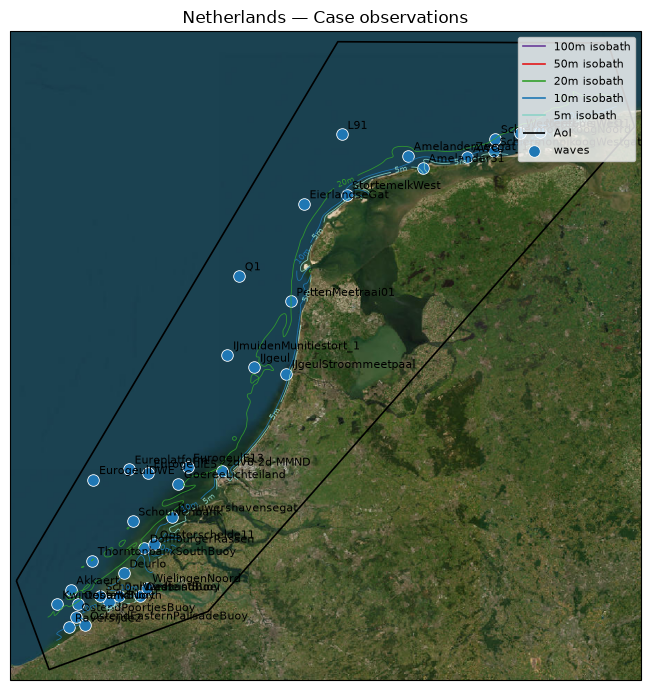

In [5]:
plot.plot_case_map(
    obs.dict_to_gdf(observations), title="Case observations", show_satellite=True
)

## Save observations JSON (GeoJSON format)

In [6]:
obs.save_geojson(feature_collection, output_path)

print(f"Wrote {len(feature_collection['features'])} feature(s) to:\n  {output_path}")

Wrote 38 feature(s) to:
  /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/Observations/Netherlands_observations.json


## Update the case JSON

After saving, add or update this key in the case JSON so downstream notebooks use your new file:

```json
"onshore_waves": "inputs/Observations/<Case>_observations.json"
```

Use the exact relative path you set in `output_observations_file`.